> **หมายเหตุ:** outputs ที่บันทึกไว้อาจเก่ากว่าโค้ดปัจจุบัน; รันเซลล์ inference ใหม่ก่อนใช้ผล และหน้าต่างสุดท้ายจะเลื่อนให้จบตรงท้ายไฟล์; ไฟล์ที่สั้นกว่า 4 วินาทีจะถูกระบุว่า limited_context

# RakForest — ทดลองเสียงใหม่และเปรียบเทียบ Single-label กับ Multi-label และ CRNN + Sigmoid

ใช้ checkpoint Multi-label รุ่น `multilabel-v1` และ Single-label ที่ฝึกไว้ แบ่งเสียงเป็นช่วงละ 4 วินาที; เปรียบเทียบผลสามโมเดลกับไฟล์เสียงที่อัปโหลด และบันทึกผลไว้ใน `reports/`.

## ข้อควรรู้ก่อนใช้

Single-label เลือกคลาสคะแนนสูงสุดเพียงหนึ่งคลาสด้วย argmax; Multi-label ให้ score แยกแต่ละคลาสและใช้ threshold 0.5 จึงอาจตอบหลายคลาสหรือไม่มีคลาสก็ได้. คะแนน Softmax กับ Sigmoid มีความหมายต่างกันและเทียบขนาดกันตรง ๆ ไม่ได้. Threshold สำหรับการตรวจทาน/แจ้งเตือนเป็นค่าเริ่มต้นเพื่อทดลอง ยังไม่ calibrate กับเสียงภาคสนาม. คะแนนไม่ยืนยันเหตุ และโมเดลยังไม่รู้จักเสียงนอกคลาสโดยอัตโนมัติ.

## วิธีทำงานของไฟล์นี้: ทดลองทำนายเสียงใหม่

ไฟล์นี้เป็นขั้น **inference/ทดลองใช้งาน checkpoint** ไม่ได้ฝึกโมเดล ใช้ checkpoint Multi-label จาก 03 และ Single-label ที่ฝึกใน 07, เตรียมเสียงใหม่ตาม sample rate/ความยาว/features เดียวกับตอนฝึก, แบ่งเป็นช่วง แล้วคำนวณ sigmoid score แยกคลาสในแต่ละช่วง; หน้าต่างสุดท้ายจะเลื่อนให้จบตรงท้ายไฟล์เพื่อให้มีเสียงจริงครบ 4 วินาที; เฉพาะไฟล์ทั้งไฟล์ที่สั้นกว่า 4 วินาทีจึงเติมความยาวและติดสถานะ `limited_context`

ผลหนึ่งช่วงจึงมีได้หลายคลาสที่คะแนนเกิน threshold พร้อมกัน ตารางผลเก็บคะแนนทุกคลาสและช่วงเวลาไว้เพื่อให้ตรวจทานได้ คะแนนและ threshold ปัจจุบันเป็นค่าทดลอง ยังไม่ใช่การแจ้งเหตุอัตโนมัติที่ผ่านการ calibrate

อัปโหลดหรือเลือกไฟล์เสียงได้จาก widget ใน notebook; ฟังผลและตรวจ false alarm/เสียงเงียบด้วยคนก่อนนำไปใช้จริง การทำนายบน notebook นี้ยังไม่เท่ากับการเชื่อม inference API เข้ากับเว็บไซต์


## 1. ติดตั้งเฉพาะ dependencies ที่ยังไม่มี

In [1]:
import importlib.util, subprocess, sys
required_modules={'torch':'torch','librosa':'librosa','soundfile':'soundfile','numpy':'numpy','pandas':'pandas','matplotlib':'matplotlib','IPython':'ipython','tqdm':'tqdm','ipywidgets':'ipywidgets'}
missing=[package for module,package in required_modules.items() if importlib.util.find_spec(module) is None]
if missing:
    print('Installing missing packages:',missing)
    subprocess.check_call([sys.executable,'-m','pip','install',*missing])
else:
    print('All required packages are already installed.')

All required packages are already installed.


## 2. Imports, paths และค่าที่ปรับได้

In [2]:
from pathlib import Path
import json, math
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import Audio, display, Markdown
from tqdm import tqdm

PROJECT_ROOT=Path.cwd()
if PROJECT_ROOT.name=='notebooks': PROJECT_ROOT=PROJECT_ROOT.parent
MODEL_PATH=PROJECT_ROOT/'models'/'rakforest_audio_cnn_multilabel_best.pt'
SINGLE_MODEL_PATH=PROJECT_ROOT/'models'/'rakforest_audio_cnn_singlelabel_retrained_best.pt'
CRNN_MODEL_PATH=PROJECT_ROOT/'models'/'rakforest_crnn_sigmoid_best.pt'
INPUT_DIR=PROJECT_ROOT/'data'/'incoming_audio'
REPORT_DIR=PROJECT_ROOT/'reports'
INPUT_DIR.mkdir(parents=True,exist_ok=True); REPORT_DIR.mkdir(parents=True,exist_ok=True)
AUDIO_EXTENSIONS={'.wav','.mp3','.flac','.ogg','.m4a','.aac','.aiff','.aif'}
BATCH_SIZE=32
RECURSIVE_INPUT=True
REVIEW_CLASSES={'fire','chainsaw','human_activity','threat_tactical','gunshot','vehicle'}
REVIEW_THRESHOLD=0.50  # provisional; calibrate on validation/field recordings later
ALERT_CLASSES={'fire','chainsaw','human_activity','threat_tactical','gunshot','vehicle'}
ALERT_THRESHOLD=0.75  # provisional; not a calibrated alarm threshold
HAS_MPS=hasattr(torch.backends,'mps') and torch.backends.mps.is_available()
DEVICE=torch.device('cuda' if torch.cuda.is_available() else ('mps' if HAS_MPS else 'cpu'))
print('Project:',PROJECT_ROOT)
print('Input folder:',INPUT_DIR)
print('Device:',DEVICE)
print('Inference uses the model window; the final full window aligns to the file end when needed.')

Project: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection
Input folder: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/data/incoming_audio
Device: mps
Inference uses the model window; the final full window aligns to the file end when needed.


## 3. โหลด checkpoint และสร้างสถาปัตยกรรมเดียวกับไฟล์ 03

In [3]:
if not MODEL_PATH.exists():
    raise FileNotFoundError(f'ไม่พบ {MODEL_PATH}; รัน 03_train_model.ipynb เพื่อฝึกโมเดลก่อน')
try:
    checkpoint=torch.load(MODEL_PATH,map_location=DEVICE,weights_only=True)
except TypeError:
    checkpoint=torch.load(MODEL_PATH,map_location=DEVICE)
if checkpoint.get('model_type')!='multilabel_audio_cnn' or checkpoint.get('schema_version')!='multilabel-v1':
    raise RuntimeError('Checkpoint นี้ยังเป็น single-label/รุ่นเก่า; รัน 03_train_model.ipynb รุ่น multi-label ให้เสร็จก่อน')
if not checkpoint.get('manifest_signature') or not checkpoint.get('training_datasets'):
    raise RuntimeError('Checkpoint เก่าขาด provenance ของชุดฝึก; ใช้ checkpoint ที่สร้างจาก 03_train_model.ipynb เวอร์ชันล่าสุด')
if 'zenodo_fire' in checkpoint['training_datasets']:
    raise RuntimeError('Checkpoint ฝึกด้วย Zenodo Fire ที่ถูกพักไว้; สร้าง manifest ใหม่และฝึกใหม่ก่อน inference')
class_order=list(checkpoint['class_names'])
if class_order!=['fire','chainsaw','vehicle','human_activity','threat_tactical','gunshot','weather','natural_ambient','silence','other']: raise RuntimeError('Checkpoint ยังไม่มี gunshot เป็นคลาสแยก; รัน 02 แล้วฝึกโมเดลใหม่ด้วย 03 ก่อน inference')
config=checkpoint['config']
if not class_order or len(class_order)!=len(set(class_order)):
    raise ValueError('Checkpoint class_names ว่างหรือมีชื่อคลาสซ้ำ')
if config.get('architecture')!='AudioCNN-v2-multilabel' or config.get('output_activation')!='sigmoid':
    raise ValueError(f"สถาปัตยกรรมใน checkpoint ไม่รองรับ: {config.get('architecture')}")
required_config={'sample_rate','duration_seconds','n_mels','n_fft','hop_length'}
missing_config=required_config-set(config)
if missing_config: raise ValueError(f'Checkpoint config ขาดค่า: {sorted(missing_config)}')
class_to_index={name:i for i,name in enumerate(class_order)}
if checkpoint.get('class_to_index',class_to_index)!=class_to_index:
    raise ValueError('class_to_index ใน checkpoint ไม่ตรงกับ class_names')
SAMPLE_RATE=int(config['sample_rate']); DURATION_SECONDS=float(config['duration_seconds'])
NUM_SAMPLES=int(SAMPLE_RATE*DURATION_SECONDS)
N_MELS=int(config['n_mels']); N_FFT=int(config['n_fft']); HOP_LENGTH=int(config['hop_length'])

class ConvBlock(nn.Module):
    def __init__(self,in_channels,out_channels):
        super().__init__()
        self.block=nn.Sequential(nn.Conv2d(in_channels,out_channels,3,padding=1,bias=False),nn.BatchNorm2d(out_channels),nn.ReLU(inplace=True),nn.MaxPool2d(2))
    def forward(self,x): return self.block(x)

class AudioCNN(nn.Module):
    def __init__(self,num_classes):
        super().__init__()
        self.features=nn.Sequential(ConvBlock(1,16),ConvBlock(16,32),ConvBlock(32,64),ConvBlock(64,128),nn.AdaptiveAvgPool2d((1,1)))
        self.classifier=nn.Sequential(nn.Flatten(),nn.Dropout(.35),nn.Linear(128,num_classes))
    def forward(self,x): return self.classifier(self.features(x))

model=AudioCNN(len(class_order)).to(DEVICE)
model.load_state_dict(checkpoint['model_state_dict']); model.eval()
print('Checkpoint epoch:',checkpoint.get('best_epoch'))
print('Validation macro-F1 (multi-label):',checkpoint.get('best_val_macro_f1'))
print('Schema:',checkpoint['schema_version'],'| output: independent sigmoid scores')
print('Classes:',class_order)
print('Training datasets:',checkpoint['training_datasets'])
print('Training manifest signature:',checkpoint['manifest_signature'][:12])

# Load the Single-label baseline for side-by-side inference on uploaded audio.
if not SINGLE_MODEL_PATH.exists():
    raise FileNotFoundError(f'ไม่พบ {SINGLE_MODEL_PATH}; รัน 07_single_vs_multi_model_comparison.ipynb ให้ฝึก Single-label checkpoint ก่อน')
try:
    single_checkpoint=torch.load(SINGLE_MODEL_PATH,map_location=DEVICE,weights_only=True)
except TypeError:
    single_checkpoint=torch.load(SINGLE_MODEL_PATH,map_location=DEVICE)
if single_checkpoint.get('model_type')!='singlelabel_audio_cnn':
    raise RuntimeError('Single checkpoint ไม่ใช่ singlelabel_audio_cnn')
if list(single_checkpoint.get('class_names',[]))!=class_order:
    raise ValueError('ลำดับคลาสของ Single และ Multi checkpoint ไม่ตรงกัน')
single_config=single_checkpoint.get('config',{})
for key in ('sample_rate','duration_seconds','n_mels','n_fft','hop_length'):
    if single_config.get(key)!=config.get(key):
        raise ValueError(f'Feature config ของ Single/Multi ไม่ตรงกันที่ {key}: {single_config.get(key)} vs {config.get(key)}')
single_model=AudioCNN(len(class_order)).to(DEVICE)
single_model.load_state_dict(single_checkpoint['model_state_dict']); single_model.eval()
print('Single-label checkpoint epoch:',single_checkpoint.get('best_epoch'))
print('Single-label validation macro-F1:',single_checkpoint.get('best_val_macro_f1'))
print('Loaded Single-label Softmax baseline alongside the Multi-label CNN Candidate.')


# Load the third model: a CRNN with temporal GRU with the same independent sigmoid outputs as Candidate.
if not CRNN_MODEL_PATH.exists():
    raise FileNotFoundError(f'ไม่พบ {CRNN_MODEL_PATH}; รัน 09_train_crnn_sigmoid.ipynb ก่อน')
try:
    crnn_checkpoint=torch.load(CRNN_MODEL_PATH,map_location=DEVICE,weights_only=True)
except TypeError:
    crnn_checkpoint=torch.load(CRNN_MODEL_PATH,map_location=DEVICE)
if crnn_checkpoint.get('schema_version')!='crnn-sigmoid-v1' or list(crnn_checkpoint.get('class_names',[]))!=class_order:
    raise ValueError('CRNN checkpoint schema/class order ไม่ตรง')
crnn_config=crnn_checkpoint.get('config',{})
for key in ('sample_rate','duration_seconds','n_mels','n_fft','hop_length'):
    if crnn_config.get(key)!=config.get(key):
        raise ValueError(f'Feature config ของ CRNN/Multi Candidate ไม่ตรงกันที่ {key}')
class CRNNConvBlock(nn.Module):
    def __init__(self,in_channels,out_channels):
        super().__init__(); self.block=nn.Sequential(nn.Conv2d(in_channels,out_channels,3,padding=1,bias=False),nn.BatchNorm2d(out_channels),nn.ReLU(inplace=True),nn.MaxPool2d(2))
    def forward(self,x): return self.block(x)

class CRNN(nn.Module):
    """CNN extracts frame features; bidirectional GRU models their temporal order."""
    def __init__(self,num_classes):
        super().__init__()
        self.features=nn.Sequential(CRNNConvBlock(1,16),CRNNConvBlock(16,32),CRNNConvBlock(32,64),CRNNConvBlock(64,128))
        self.gru=nn.GRU(input_size=128,hidden_size=64,num_layers=1,batch_first=True,bidirectional=True)
        self.dropout=nn.Dropout(.35)
        self.classifier=nn.Linear(128,num_classes)
    def forward(self,x):
        z=self.features(x)              # [batch, channels, mel_bins, time_steps]
        z=z.mean(dim=2).transpose(1,2)  # [batch, time_steps, channels]
        sequence,_=self.gru(z)
        pooled=sequence.mean(dim=1)
        return self.classifier(self.dropout(pooled))


crnn_model=CRNN(len(class_order)).to(DEVICE)
crnn_model.load_state_dict(crnn_checkpoint['model_state_dict']); crnn_model.eval()
print('CRNN + Sigmoid checkpoint epoch:',crnn_checkpoint.get('best_epoch'))
print('CRNN validation macro-F1:',crnn_checkpoint.get('best_val_macro_f1'))


Checkpoint epoch: 18
Validation macro-F1 (multi-label): 0.7513443953670111
Schema: multilabel-v1 | output: independent sigmoid scores
Classes: ['fire', 'chainsaw', 'vehicle', 'human_activity', 'threat_tactical', 'gunshot', 'weather', 'natural_ambient', 'silence', 'other']
Training datasets: ['c3gd', 'datasec_v2', 'esc50', 'fire_google_drive', 'footstep_set', 'fsc22', 'm16_gunshots', 'nonspeech7k', 'rfcx_frugalai', 'tropical_forest_gunshot', 'vehicle_sounds', 'vocalsound', 'zenodo_gunshot']
Training manifest signature: 71cb4013edba
Single-label checkpoint epoch: 18
Single-label validation macro-F1: 0.8127256824927217
Loaded Single-label Softmax baseline alongside the Multi-label CNN Candidate.
CRNN + Sigmoid checkpoint epoch: 20
CRNN validation macro-F1: 0.7369501761589003


In [4]:
import ipywidgets as widgets
from IPython.display import display

uploader=widgets.FileUpload(
    accept=','.join(sorted(AUDIO_EXTENSIONS)),
    multiple=True,
    description='เลือกไฟล์เสียง'
)
display(uploader)
print('เลือกไฟล์เสียงด้านบน แล้วรันเซลล์ถัดไปเพื่อบันทึก')

FileUpload(value=(), accept='.aac,.aif,.aiff,.flac,.m4a,.mp3,.ogg,.wav', description='เลือกไฟล์เสียง', multipl…

เลือกไฟล์เสียงด้านบน แล้วรันเซลล์ถัดไปเพื่อบันทึก


In [5]:
import shutil

def unique_destination(folder,name):
    candidate=folder/Path(name).name
    if not candidate.exists(): return candidate
    stem,suffix=candidate.stem,candidate.suffix
    counter=1
    while True:
        candidate=folder/f'{stem}_{counter}{suffix}'
        if not candidate.exists(): return candidate
        counter+=1

def uploaded_items(value):
    # ipywidgets 7 uses a dict; version 8 uses a tuple of file metadata dicts.
    if isinstance(value,dict):
        for name,metadata in value.items():
            yield name,metadata.get('content',b'')
    else:
        for metadata in value:
            yield metadata.get('name','audio'),metadata.get('content',b'')

uploaded=list(uploaded_items(uploader.value))
if not uploaded:
    print('ยังไม่มีไฟล์อัปโหลด; วางไฟล์ไว้ใน incoming_audio ด้วยตนเองได้')
else:
    saved=[]
    for name,content in uploaded:
        safe_name=Path(name).name
        if Path(safe_name).suffix.lower() not in AUDIO_EXTENSIONS:
            print('ข้ามไฟล์นามสกุลที่ไม่รองรับ:',safe_name); continue
        destination=unique_destination(INPUT_DIR,safe_name)
        destination.write_bytes(bytes(content))
        saved.append(destination)
    print(f'บันทึก {len(saved)} ไฟล์ลง {INPUT_DIR}')
    for path in saved: print(' -',path.name)

ยังไม่มีไฟล์อัปโหลด; วางไฟล์ไว้ใน incoming_audio ด้วยตนเองได้


## 4. อัปโหลดไฟล์เสียงเพื่อทำนาย

รันเซลล์ถัดไปเพื่อแสดงปุ่มเลือกไฟล์เสียง แล้วเลือกไฟล์จากเครื่องได้หลายไฟล์ เมื่อเลือกเสร็จให้รันเซลล์บันทึกไฟล์ ไฟล์จะถูกเก็บไว้ใน `data/incoming_audio/` และเซลล์ถัดไปจะพบไฟล์เหล่านั้นสำหรับ inference. หากเพิ่งติดตั้ง `ipywidgets` แต่ปุ่มไม่แสดง ให้ restart kernel แล้วรันเซลล์ตามลำดับอีกครั้ง.

In [6]:
searcher=INPUT_DIR.rglob('*') if RECURSIVE_INPUT else INPUT_DIR.glob('*')
audio_paths=sorted(p for p in searcher if p.is_file() and p.suffix.lower() in AUDIO_EXTENSIONS and not p.name.startswith('.'))
print(f'Found {len(audio_paths):,} audio files')
if not audio_paths:
    print(f'ยังไม่พบไฟล์เสียง ให้วางไฟล์ใน {INPUT_DIR} แล้วรัน cell นี้ใหม่')
else:
    display(pd.DataFrame({'file':[str(p.relative_to(PROJECT_ROOT)) for p in audio_paths]}).head(30))

Found 4 audio files


,file
0,data/incoming_audio/70895_somerset_fire_1.mp3
1,data/incoming_audio/Car Passing By - Sound Eff...
2,data/incoming_audio/City Rain at Night Night T...
3,data/incoming_audio/ScreenRecording_11-09-2569...


## 5. Preprocessing ให้ตรงกับ 02 และ feature extraction ให้ตรงกับ 03

In [7]:
def read_audio_mono(path):
    try:
        y,sr=sf.read(path,dtype='float32',always_2d=False)
        if y.ndim==2: y=y.mean(axis=1)
    except Exception:
        # Fallback decoder for formats such as MP3/M4A when libsndfile lacks codec support.
        y,sr=librosa.load(path,sr=None,mono=True,dtype=np.float32)
    return np.asarray(y,dtype=np.float32),int(sr)

def load_and_segment(path):
    y,sr=read_audio_mono(path)
    if y.size==0: return [],int(sr)
    y-=float(np.mean(y))  # DC offset removal, same as 02
    if sr!=SAMPLE_RATE: y=librosa.resample(y,orig_sr=sr,target_sr=SAMPLE_RATE)
    if len(y)<=NUM_SAMPLES:
        valid_samples=len(y)
        segment=np.pad(y,(0,NUM_SAMPLES-valid_samples)) if valid_samples<NUM_SAMPLES else y
        return [(segment.astype(np.float32),0.0,valid_samples/SAMPLE_RATE)],int(sr)
    # Keep the normal 4-second blocks, then align one final full window to the end
    # instead of classifying a tiny padded tail on its own.
    starts=list(range(0,len(y)-NUM_SAMPLES+1,NUM_SAMPLES))
    final_start=len(y)-NUM_SAMPLES
    if starts[-1]!=final_start: starts.append(final_start)
    segments=[]
    for start in starts:
        segment=y[start:start+NUM_SAMPLES]
        segments.append((segment.astype(np.float32),start/SAMPLE_RATE,DURATION_SECONDS))
    return segments,int(sr)

def to_logmel(y):
    mel=librosa.feature.melspectrogram(y=y,sr=SAMPLE_RATE,n_fft=N_FFT,hop_length=HOP_LENGTH,n_mels=N_MELS,power=2.0)
    logmel=librosa.power_to_db(mel,ref=np.max)
    return ((logmel-logmel.mean())/(logmel.std()+1e-6)).astype(np.float32)

print(f'Input standardization: mono, {SAMPLE_RATE} Hz, {DURATION_SECONDS:g} seconds per segment')

Input standardization: mono, 16000 Hz, 4 seconds per segment


## 6. รันทำนายและบันทึกผล

In [8]:
rows=[]; failures=[]
for path in tqdm(audio_paths,desc='Predict audio files'):
    try:
        segments,original_sr=load_and_segment(path)
        if not segments:
            failures.append({'file':str(path),'error':'empty audio'}); continue
        for batch_start in range(0,len(segments),BATCH_SIZE):
            batch_segments=segments[batch_start:batch_start+BATCH_SIZE]
            xb=torch.from_numpy(np.stack([to_logmel(item[0]) for item in batch_segments])).unsqueeze(1).to(DEVICE)
            with torch.no_grad(): probs=torch.sigmoid(model(xb)).cpu().numpy()
            for offset,((_,start_seconds,valid_seconds),prob) in enumerate(zip(batch_segments,probs)):
                limited_context=valid_seconds < DURATION_SECONDS
                predicted=[name for i,name in enumerate(class_order) if prob[i]>=REVIEW_THRESHOLD]
                review_score=max((float(prob[class_to_index[name]]) for name in REVIEW_CLASSES if name in class_to_index),default=0.0)
                alert_score=max((float(prob[class_to_index[name]]) for name in ALERT_CLASSES if name in class_to_index),default=0.0)
                rows.append({
                    'file':str(path.relative_to(PROJECT_ROOT)),
                    'segment_index':batch_start+offset,
                    'start_seconds':round(start_seconds,3),
                    'end_seconds':round(start_seconds+valid_seconds,3),
                    'valid_seconds':round(valid_seconds,3),
                    'status':'limited_context' if limited_context else 'predicted',
                    'predicted_labels':predicted,
                    'predicted_labels_text':('limited context: ' if limited_context else '')+(', '.join(predicted) if predicted else 'no class above review threshold'),
                    'max_score':float(prob.max()),
                    'review_score':review_score,
                    'alert_score':alert_score,
                    'review_recommended':limited_context or any(name in REVIEW_CLASSES and prob[j]>=REVIEW_THRESHOLD for j,name in enumerate(class_order)),
                    'high_priority_candidate':(not limited_context) and any(name in ALERT_CLASSES and prob[j]>=ALERT_THRESHOLD for j,name in enumerate(class_order)),
                    **{f'prob_{name}':float(prob[j]) for j,name in enumerate(class_order)},
                })
    except Exception as e:
        failures.append({'file':str(path),'error':f'{type(e).__name__}: {e}'})

predictions=pd.DataFrame(rows)
if predictions.empty:
    print('ไม่มี segment ที่ทำนายได้')
else:
    predictions=predictions.sort_values(['file','segment_index']).reset_index(drop=True)
    predictions_path=REPORT_DIR/'inference_predictions.csv'
    predictions.to_csv(predictions_path,index=False)
    summary=(predictions.groupby('file').agg(
        segments=('segment_index','count'),
        predicted_segments=('status',lambda s:int(s.eq('predicted').sum())),
        limited_context_segments=('status',lambda s:int(s.eq('limited_context').sum())),
        review_segments=('review_recommended','sum'),
        high_priority_segments=('high_priority_candidate','sum'),
        max_score=('max_score','max'),
        mean_score=('max_score','mean')
    ).reset_index())
    summary['detected_classes']=summary.file.map(lambda filename:', '.join(sorted({label for labels in predictions.loc[predictions.file.eq(filename)&predictions.status.eq('predicted'),'predicted_labels'] for label in labels})))
    summary['limited_context_candidates']=summary.file.map(lambda filename:', '.join(sorted({label for labels in predictions.loc[predictions.file.eq(filename)&predictions.status.eq('limited_context'),'predicted_labels'] for label in labels})))
    summary_path=REPORT_DIR/'inference_file_summary.csv'; summary.to_csv(summary_path,index=False)
    display(predictions[['file','start_seconds','end_seconds','valid_seconds','status','predicted_labels_text','review_score','alert_score']+[f'prob_{c}' for c in class_order]].head(30))
    display(summary.sort_values(['high_priority_segments','review_segments'],ascending=False).head(30))
    print('Final windows are aligned to the file end; only recordings shorter than one model window are padded and marked limited_context.')
    print('Saved:',predictions_path)
    print('Saved:',summary_path)
if failures:
    failures_path=REPORT_DIR/'inference_failures.csv'
    pd.DataFrame(failures).to_csv(failures_path,index=False)
    display(pd.DataFrame(failures))
    print('Saved:',failures_path)


Predict audio files:   0%|          | 0/4 [00:00<?, ?it/s]

Predict audio files: 100%|██████████| 4/4 [00:01<00:00,  2.03it/s]


,file,start_seconds,end_seconds,valid_seconds,status,predicted_labels_text,review_score,alert_score,prob_fire,prob_chainsaw,prob_vehicle,prob_human_activity,prob_threat_tactical,prob_gunshot,prob_weather,prob_natural_ambient,prob_silence,prob_other
0,data/incoming_audio/70895_somerset_fire_1.mp3,0.000,4.000,4.0,predicted,"fire, vehicle, weather",0.773639,0.773639,0.697893,0.002613,0.773639,0.170645,0.095514,0.013086,0.552629,0.148154,0.011515,0.081598
1,data/incoming_audio/70895_somerset_fire_1.mp3,4.000,8.000,4.0,predicted,"fire, vehicle, weather, natural_ambient",0.902917,0.902917,0.855195,0.005744,0.902917,0.274389,0.175807,0.012437,0.853913,0.591345,0.038639,0.073343
2,data/incoming_audio/70895_somerset_fire_1.mp3,8.000,12.000,4.0,predicted,"fire, vehicle, weather",0.751619,0.751619,0.751619,0.002052,0.712515,0.101529,0.120711,0.008407,0.848926,0.365804,0.027528,0.075728
3,data/incoming_audio/70895_somerset_fire_1.mp3,11.185,15.185,4.0,predicted,"fire, weather",0.898391,0.898391,0.898391,0.000142,0.195600,0.308799,0.118360,0.005370,0.662169,0.045108,0.000985,0.020392
4,data/incoming_audio/Car Passing By - Sound Eff...,0.000,4.000,4.0,predicted,"vehicle, other",0.981233,0.981233,0.001242,0.001968,0.981233,0.007210,0.012413,0.046551,0.188854,0.016841,0.018174,0.602480
5,data/incoming_audio/Car Passing By - Sound Eff...,1.968,5.968,4.0,predicted,human_activity,0.904602,0.904602,0.000184,0.000433,0.355836,0.904602,0.000656,0.040891,0.034647,0.000849,0.000013,0.147398
6,data/incoming_audio/City Rain at Night Night T...,0.000,4.000,4.0,predicted,"vehicle, natural_ambient, other",0.811694,0.811694,0.039896,0.060534,0.811694,0.070727,0.128990,0.022141,0.484058,0.691626,0.254848,0.565865
7,data/incoming_audio/City Rain at Night Night T...,4.000,8.000,4.0,predicted,"fire, vehicle, weather",0.594715,0.594715,0.574757,0.040031,0.594715,0.136110,0.095360,0.237075,0.601324,0.359832,0.101837,0.464298
8,data/incoming_audio/City Rain at Night Night T...,8.000,12.000,4.0,predicted,"vehicle, weather",0.837108,0.837108,0.204281,0.014202,0.837108,0.143370,0.070003,0.242191,0.605004,0.181403,0.138717,0.393105
9,data/incoming_audio/City Rain at Night Night T...,12.000,16.000,4.0,predicted,"vehicle, weather",0.884210,0.884210,0.054542,0.004925,0.884210,0.051168,0.052189,0.260015,0.778637,0.042061,0.206739,0.436421


,file,segments,predicted_segments,limited_context_segments,review_segments,high_priority_segments,max_score,mean_score,detected_classes,limited_context_candidates
2,data/incoming_audio/City Rain at Night Night T...,23,23,0,23,9,0.963985,0.751860,"fire, natural_ambient, other, vehicle, weather",
0,data/incoming_audio/70895_somerset_fire_1.mp3,4,4,0,4,4,0.902917,0.855968,"fire, natural_ambient, vehicle, weather",
3,data/incoming_audio/ScreenRecording_11-09-2569...,7,7,0,4,3,0.952989,0.743251,"fire, gunshot, human_activity, natural_ambient...",
1,data/incoming_audio/Car Passing By - Sound Eff...,2,2,0,2,2,0.981233,0.942918,"human_activity, other, vehicle",


Final windows are aligned to the file end; only recordings shorter than one model window are padded and marked limited_context.
Saved: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/inference_predictions.csv
Saved: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/inference_file_summary.csv


## 7. เปรียบเทียบเสียงที่อัปโหลด: Single-label, Multi-label Candidate และ CRNN + Sigmoid

เซลล์นี้ประมวลผลไฟล์ที่อัปโหลดด้วยโมเดลทั้งสอง แล้วทำกราฟแท่งคะแนนของทั้งสามโมเดลแยกตามคลาสสำหรับแต่ละไฟล์ (ใช้ค่าเฉลี่ยคะแนนจากทุกช่วงของไฟล์) พร้อมบันทึกผลรายช่วงและกราฟไว้ใน `reports/`

Single-label เลือกคำตอบเดียวด้วย `argmax`; Multi-label ตัดสินแต่ละคลาสด้วย threshold 0.5. **Softmax และ Sigmoid มีความหมายคะแนนต่างกัน ความสูงแท่งจึงใช้เทียบตรง ๆ ไม่ได้** กราฟมีไว้ดูรูปแบบคำตอบของสามโมเดลเท่านั้น ไม่ใช่การยืนยันชนิดเสียงจริง


Compare all three models: 100%|██████████| 4/4 [00:00<00:00, 12.27it/s]


,file,segment_index,start_seconds,end_seconds,status,single_label,candidate_labels,crnn_labels
0,data/incoming_audio/70895_somerset_fire_1.mp3,0,0.000,4.000,predicted,weather,"fire, vehicle, weather","fire, vehicle, weather"
1,data/incoming_audio/70895_somerset_fire_1.mp3,1,4.000,8.000,predicted,weather,"fire, vehicle, weather, natural_ambient","fire, vehicle"
2,data/incoming_audio/70895_somerset_fire_1.mp3,2,8.000,12.000,predicted,weather,"fire, vehicle, weather","fire, vehicle, weather"
3,data/incoming_audio/70895_somerset_fire_1.mp3,3,11.185,15.185,predicted,weather,"fire, weather","fire, vehicle, weather"
4,data/incoming_audio/Car Passing By - Sound Eff...,0,0.000,4.000,predicted,vehicle,"vehicle, other",vehicle
5,data/incoming_audio/Car Passing By - Sound Eff...,1,1.968,5.968,predicted,vehicle,human_activity,"vehicle, other"
6,data/incoming_audio/City Rain at Night Night T...,0,0.000,4.000,predicted,weather,"vehicle, natural_ambient, other",weather
7,data/incoming_audio/City Rain at Night Night T...,1,4.000,8.000,predicted,vehicle,"fire, vehicle, weather",weather
8,data/incoming_audio/City Rain at Night Night T...,2,8.000,12.000,predicted,vehicle,"vehicle, weather","vehicle, weather"
9,data/incoming_audio/City Rain at Night Night T...,3,12.000,16.000,predicted,vehicle,"vehicle, weather","vehicle, weather"


Saved per-segment three-model scores: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/inference_three_model_comparison.csv


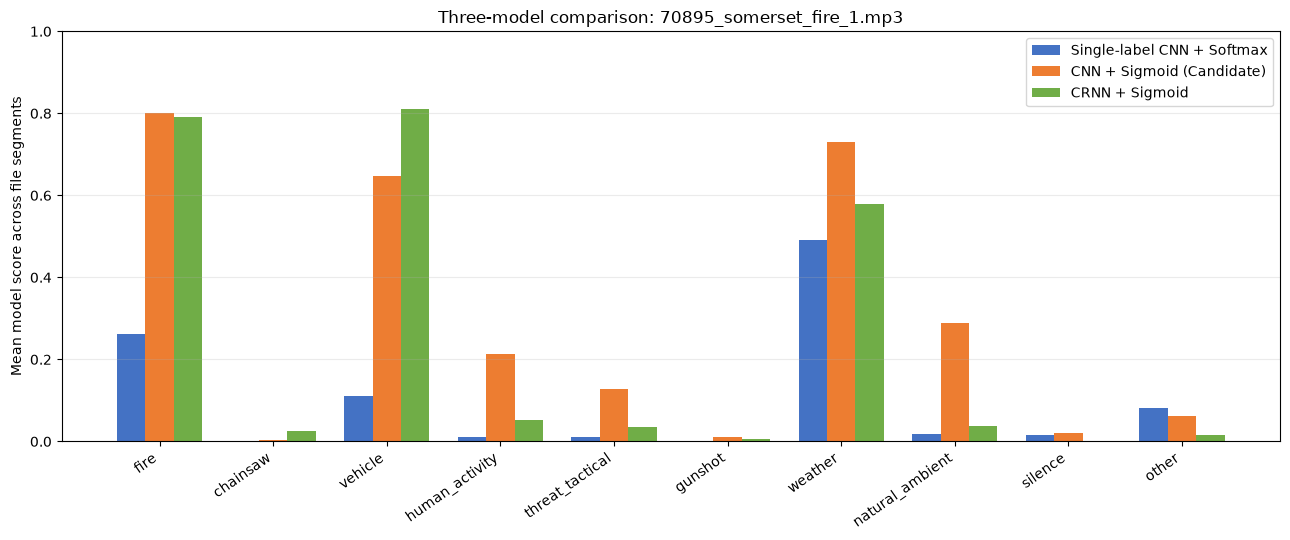

Saved comparison graph: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/inference_three_model_70895_somerset_fire_1.png


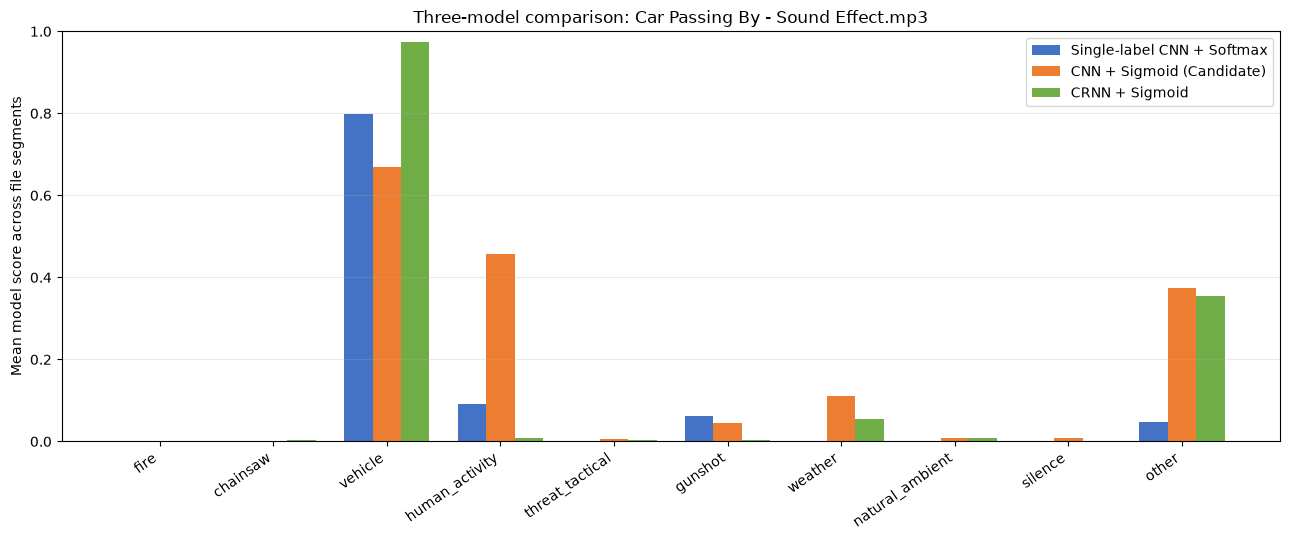

Saved comparison graph: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/inference_three_model_Car_Passing_By_-_Sound_Effect.png


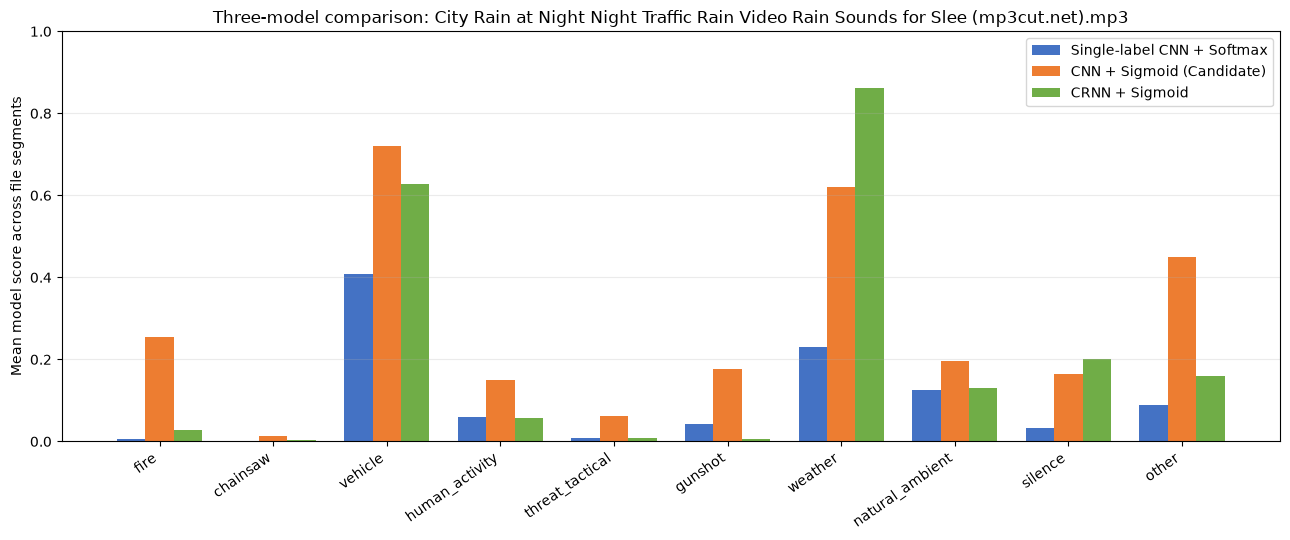

Saved comparison graph: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/inference_three_model_City_Rain_at_Night_Night_Traffic_Rain_Video_Rain_Sounds_for_Slee_mp3cut.net.png


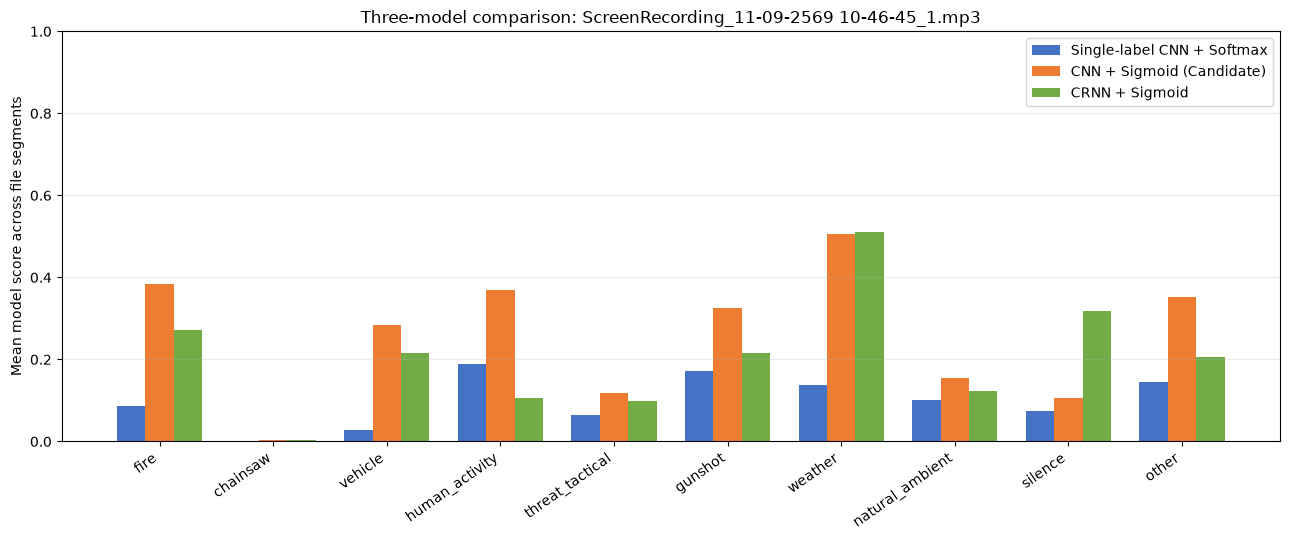

Saved comparison graph: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/inference_three_model_ScreenRecording_11-09-2569_10-46-45_1.png


In [9]:
if not audio_paths:
    print('อัปโหลดไฟล์เสียงหรือวางไฟล์ใน incoming_audio แล้วรัน cell นี้อีกครั้ง')
else:
    import re
    comparison_rows=[]
    for path in tqdm(audio_paths,desc='Compare all three models'):
        try:
            segments,original_sr=load_and_segment(path)
            if not segments:
                print('ข้ามไฟล์เสียงว่าง:',path.name)
                continue
            for batch_start in range(0,len(segments),BATCH_SIZE):
                batch_segments=segments[batch_start:batch_start+BATCH_SIZE]
                features=np.stack([to_logmel(item[0]) for item in batch_segments])
                xb=torch.from_numpy(features).unsqueeze(1).to(DEVICE)
                with torch.no_grad():
                    single_scores=torch.softmax(single_model(xb),dim=1).cpu().numpy()
                    candidate_scores=torch.sigmoid(model(xb)).cpu().numpy()
                    crnn_scores=torch.sigmoid(crnn_model(xb)).cpu().numpy()
                for offset,((_,start_seconds,valid_seconds),sp,mp,cp) in enumerate(zip(batch_segments,single_scores,candidate_scores,crnn_scores)):
                    row={
                        'file':str(path.relative_to(PROJECT_ROOT)),
                        'segment_index':batch_start+offset,
                        'start_seconds':round(start_seconds,3),
                        'end_seconds':round(start_seconds+valid_seconds,3),
                        'status':'limited_context' if valid_seconds<DURATION_SECONDS else 'predicted',
                        'single_label':class_order[int(np.argmax(sp))],
                        'candidate_labels':', '.join(name for j,name in enumerate(class_order) if mp[j]>=REVIEW_THRESHOLD) or 'none above threshold',
                        'crnn_labels':', '.join(name for j,name in enumerate(class_order) if cp[j]>=REVIEW_THRESHOLD) or 'none above threshold',
                    }
                    for j,name in enumerate(class_order):
                        row[f'single_score_{name}']=float(sp[j])
                        row[f'candidate_score_{name}']=float(mp[j])
                        row[f'crnn_score_{name}']=float(cp[j])
                    comparison_rows.append(row)
        except Exception as e:
            print(f'เปรียบเทียบ {path.name} ไม่สำเร็จ: {type(e).__name__}: {e}')

    three_model_comparison=pd.DataFrame(comparison_rows)
    if three_model_comparison.empty:
        print('ไม่มีไฟล์ที่เปรียบเทียบได้')
    else:
        comparison_path=REPORT_DIR/'inference_three_model_comparison.csv'
        three_model_comparison.to_csv(comparison_path,index=False)
        display(three_model_comparison[['file','segment_index','start_seconds','end_seconds','status','single_label','candidate_labels','crnn_labels']].head(30))
        print('Saved per-segment three-model scores:',comparison_path)
        for filename,group in three_model_comparison.groupby('file',sort=False):
            mean_scores=np.array([
                [group[f'single_score_{name}'].mean() for name in class_order],
                [group[f'candidate_score_{name}'].mean() for name in class_order],
                [group[f'crnn_score_{name}'].mean() for name in class_order],
            ])
            x=np.arange(len(class_order)); width=.25
            fig,ax=plt.subplots(figsize=(13,5.5))
            ax.bar(x-width,mean_scores[0],width,label='Single-label CNN + Softmax',color='#4472C4')
            ax.bar(x,mean_scores[1],width,label='CNN + Sigmoid (Candidate)',color='#ED7D31')
            ax.bar(x+width,mean_scores[2],width,label='CRNN + Sigmoid',color='#70AD47')
            ax.set_xticks(x,class_order,rotation=35,ha='right')
            ax.set_ylim(0,1); ax.set_ylabel('Mean model score across file segments')
            ax.set_title(f'Three-model comparison: {Path(filename).name}')
            ax.grid(axis='y',alpha=.25); ax.legend(loc='upper right')
            fig.tight_layout()
            safe_name=re.sub(r'[^A-Za-z0-9._-]+','_',Path(filename).stem).strip('_')[:100]
            graph_path=REPORT_DIR/f'inference_three_model_{safe_name}.png'
            fig.savefig(graph_path,dpi=180,bbox_inches='tight')
            plt.show()
            print('Saved comparison graph:',graph_path)


## 8. ฟังตัวอย่างที่ควรตรวจ
เล่นช่วงที่ได้ review score สูงสุดไม่เกิน 10 ช่วง; แต่ละช่วงอาจมีหลาย label.

In [10]:
if not predictions.empty:
    preview=predictions[predictions.review_recommended].sort_values('review_score',ascending=False).head(10)
    for row in preview.itertuples():
        audio_path=PROJECT_ROOT/row.file
        start=int(row.start_seconds*SAMPLE_RATE)
        y,sr=read_audio_mono(audio_path)
        if sr!=SAMPLE_RATE: y=librosa.resample(y,orig_sr=sr,target_sr=SAMPLE_RATE)
        y=y[start:start+NUM_SAMPLES]
        display(Markdown(f'### {row.predicted_labels_text} | review score {row.review_score:.3f} | {row.file} @ {row.start_seconds:.1f}s'))
        display(Audio(y,rate=SAMPLE_RATE))
else:
    print('รันทำนายก่อน แล้วจึงแสดงตัวอย่างเสียงได้')


### vehicle, other | review score 0.981 | data/incoming_audio/Car Passing By - Sound Effect.mp3 @ 0.0s

### vehicle | review score 0.964 | data/incoming_audio/City Rain at Night Night Traffic Rain Video Rain Sounds for Slee (mp3cut.net).mp3 @ 24.0s

### human_activity | review score 0.953 | data/incoming_audio/ScreenRecording_11-09-2569 10-46-45_1.mp3 @ 8.0s

### vehicle, weather | review score 0.940 | data/incoming_audio/City Rain at Night Night Traffic Rain Video Rain Sounds for Slee (mp3cut.net).mp3 @ 16.0s

### vehicle | review score 0.934 | data/incoming_audio/City Rain at Night Night Traffic Rain Video Rain Sounds for Slee (mp3cut.net).mp3 @ 28.0s

### vehicle, weather | review score 0.908 | data/incoming_audio/City Rain at Night Night Traffic Rain Video Rain Sounds for Slee (mp3cut.net).mp3 @ 20.0s

### human_activity | review score 0.905 | data/incoming_audio/Car Passing By - Sound Effect.mp3 @ 2.0s

### fire, vehicle, weather, natural_ambient | review score 0.903 | data/incoming_audio/70895_somerset_fire_1.mp3 @ 4.0s

### fire, weather | review score 0.898 | data/incoming_audio/70895_somerset_fire_1.mp3 @ 11.2s

### fire, weather | review score 0.886 | data/incoming_audio/ScreenRecording_11-09-2569 10-46-45_1.mp3 @ 16.0s

## Outputs และขอบเขตการใช้งาน

- `reports/inference_predictions.csv`: ผลรายช่วง มีหลาย label และ score แยกคลาส; ช่วงของไฟล์ที่สั้นกว่า 4 วินาทีติดสถานะ `limited_context`
- `reports/inference_file_summary.csv`: คลาสที่พบ จำนวนช่วงที่ควรตรวจ และจำนวนช่วงที่มีบริบทสั้น
- `reports/inference_failures.csv`: ไฟล์ที่อ่านหรือทำนายไม่สำเร็จ (ถ้ามี)
- `reports/inference_three_model_comparison.csv`: ผลเปรียบเทียบทั้งสามโมเดลรายช่วงของไฟล์ที่อัปโหลด
- `reports/inference_three_model_<ชื่อไฟล์>.png`: กราฟแท่งคะแนนเฉลี่ยแยกตามคลาสของแต่ละไฟล์

Threshold 0.5/0.75 เป็นค่าเริ่มต้นที่ยังไม่ calibrate; `high_priority_candidate` ไม่ใช่คำสั่งแจ้งเหตุอัตโนมัติ ควรตรวจเสียงจริงและปรับเกณฑ์จาก validation/ข้อมูลภาคสนามก่อนใช้งานจริง. `silence` และ `other` เป็นแท็กเดี่ยว ไม่คาดว่าจะเกิดพร้อมคลาสอื่น.